In [1]:
####################### Min, Max, Mean Currents, Waves, Bed Stress #####################
# The purpose of this script is to plot the min, max, and means for currents, 
# waves, and bed shear stress in response to reviewers' comments to show more about the 
# hydrodynamic conditions during our simulated period (without repeating 
# Undzis et al. (2025) too much)
#
# Notes:
# - This runs best in xroms
#
###################################################################################

In [2]:
# Load in the packages 
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap
import cartopy.mpl.ticker as cticker
import cmocean
from shapely.geometry import Polygon
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle
import os
import matplotlib.colors as mcolors
from matplotlib import colors
from matplotlib import cm, ticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, LogLocator, LogFormatterExponent, LogFormatterSciNotation, LogFormatter)
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
import cartopy.crs as ccrs
import matplotlib.ticker as tick
from matplotlib import cm, ticker
import datetime
import warnings
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogFormatterExponent
crs = ccrs.PlateCarree()
warnings.filterwarnings("ignore") #turns off annoying warnings
#Cartopy
land_10m = cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                edgecolor='face',
                                facecolor=cfeature.COLORS['land'])

In [3]:
# set a universal fontsize 
fontsize = 20 # 32 #20

# Set the tick size for all plots
matplotlib.rc('xtick', labelsize=fontsize) 
matplotlib.rc('ytick', labelsize=fontsize)

# Prevent tick labels from overlapping
matplotlib.rcParams['xtick.major.pad'] = 12 # 28 # 12
matplotlib.rcParams['ytick.major.pad'] = 12 # 18 # 12

In [4]:
# Load in the model grid
#grid = xr.open_dataset('/Users/brun1463/Desktop/Research_Lab/Kaktovik_Alaska_2019/Code/Grids/KakAKgrd_shelf_big010_smooth006.nc') 
grid = xr.open_dataset('/projects/brun1463/ROMS/Kakak3_Alpine/Include/KakAKgrd_shelf_big010_smooth006.nc')

# Pull out some dimensions
eta_rho_len = len(grid.eta_rho)
xi_rho_len = len(grid.xi_rho)
s_rho_len = int(20)

In [5]:
# Load in the rho masks 
mask_rho_nan = xr.open_dataset('/projects/brun1463/ROMS/Kakak3_Alpine/Scripts_2/Analysis/Nudge_masks/nudge_mask_rho_ones_nans.nc') # UPDATE PATH


In [6]:
# Load the model output
# Unaggregated
model_output = xr.open_mfdataset('/pl/active/moriarty_lab/BriannaU/Paper2/Model_Output/Unaggregated/dbsed0001_10rivs_unaggregated/ocean_avg_beaufort_rivers_10rivs_13seabed_unaggregated_dbsed0001_*.nc')

# Trim to period we want
model_output = model_output.isel(ocean_time=slice(0, 738))

In [7]:
# Load in the wave forcing file
wave_frc = xr.open_dataset('/projects/brun1463/ROMS/Beaufort_Shelf_Rivers_Alpine_002/Include/wave_forcing_file_kaktovik_shelf_cop_2020_data002.nc')

In [8]:
# Get time for the wave data
time_data_wave = pd.to_datetime(wave_frc.wave_time.values+86400, origin=datetime.datetime(1999,12,31), unit='s')

### Prep the Data

*Currents*

In [9]:
# Get the min depth-averaged currents 
# Ubar
min_ubar_east = model_output.ubar_eastward.min(dim='ocean_time').compute()
print(np.shape(min_ubar_east))
max_ubar_east = model_output.ubar_eastward.max(dim='ocean_time').compute()
mean_ubar_east = model_output.ubar_eastward.mean(dim='ocean_time').compute()

# Vbar 
# Ubar
min_vbar_north = model_output.vbar_northward.min(dim='ocean_time').compute()
print(np.shape(min_vbar_north))
max_vbar_north = model_output.vbar_northward.max(dim='ocean_time').compute()
mean_vbar_north = model_output.vbar_northward.mean(dim='ocean_time').compute()

(206, 608)
(206, 608)


In [10]:
# Get the depth-avg current magnitude and calculate min, max, mean
depth_avg_cur_mag = np.sqrt((model_output.ubar_eastward**2)+(model_output.vbar_northward*2))

min_depth_avg_cur_mag = depth_avg_cur_mag.min(dim='ocean_time').compute()
max_depth_avg_cur_mag = depth_avg_cur_mag.max(dim='ocean_time').compute()
mean_depth_avg_cur_mag = depth_avg_cur_mag.mean(dim='ocean_time').compute()

*Waves*

In [11]:
# Find overlappin times for waves and output
print(time_data_wave[-51])
print(model_output.ocean_time[-1].values)

2020-10-31 23:00:00
2020-10-31T23:00:00.000000000


In [12]:
# Get the min, max, mean significant wave height 
min_Hwave = wave_frc.Hwave[:-52,:,:].min(dim='wave_time').compute()
max_Hwave = wave_frc.Hwave[:-52,:,:].max(dim='wave_time').compute()
mean_Hwave = wave_frc.Hwave[:-52,:,:].mean(dim='wave_time').compute()


*Bed Shear Stress*

In [44]:
# Compute min, max, and mean bed shear stress 
min_bstrcwmax = model_output.bstrcwmax.min(dim='ocean_time').compute()
max_bstrcwmax = model_output.bstrcwmax.max(dim='ocean_time').compute()
mean_bstrcwmax = model_output.bstrcwmax.mean(dim='ocean_time').compute()

### Plot!  
Make a plot of these!

In [45]:
# Trim and mask things for plotting 
# Set the number of cells in the sponge on each open boundary
c_west = 36
c_north = 45
c_east = 36

# Make it so land will appear
temp_mask = grid.mask_rho.copy()
temp_mask = np.where(temp_mask==0, np.nan, temp_mask)

# Mask and trim things 
# Current magnitude
min_depth_avg_cur_mag_masked = min_depth_avg_cur_mag*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
min_depth_avg_cur_mag_masked_trimmed = min_depth_avg_cur_mag_masked[:,c_west:-c_west]
max_depth_avg_cur_mag_masked = max_depth_avg_cur_mag*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
max_depth_avg_cur_mag_masked_trimmed = max_depth_avg_cur_mag_masked[:,c_west:-c_west]
mean_depth_avg_cur_mag_masked = mean_depth_avg_cur_mag*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
mean_depth_avg_cur_mag_masked_trimmed = mean_depth_avg_cur_mag_masked[:,c_west:-c_west]

# Significant wave height 
min_Hwave_masked = min_Hwave*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
min_Hwave_masked_trimmed = min_Hwave_masked[:,c_west:-c_west]
max_Hwave_masked = max_Hwave*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
max_Hwave_masked_trimmed = max_Hwave_masked[:,c_west:-c_west]
mean_Hwave_masked = mean_Hwave*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
mean_Hwave_masked_trimmed = mean_Hwave_masked[:,c_west:-c_west]

# Bed shear stress 
min_bstrcwmax_masked = min_bstrcwmax*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
min_bstrcwmax_masked_trimmed = min_bstrcwmax_masked[:,c_west:-c_west]
max_bstrcwmax_masked = max_bstrcwmax*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
max_bstrcwmax_masked_trimmed = max_bstrcwmax_masked[:,c_west:-c_west]
mean_bstrcwmax_masked = mean_bstrcwmax*grid.mask_rho.values*mask_rho_nan.nudge_mask_rho_nan
mean_bstrcwmax_masked_trimmed = mean_bstrcwmax_masked[:,c_west:-c_west]

# Lat/lon
lon_rho_trimmed = grid.lon_rho[:,c_west:-c_west].values
lat_rho_trimmed = grid.lat_rho[:,c_west:-c_west].values

In [15]:
river_marker_colors = ['#FC440F', '#F5ED00', '#5EF38C', '#26532B', '#F43ECF', '#9C00A8',
                       '#0115F5', '#00A6A6', '#AB64EB', '#D44179', '#08E0E3', '#B27009', '#EA8D40']

In [47]:
# Set min, max and levels for currents
vmin_cur = 0.0 # m/s
vmax_cur = 0.8 #  m/s
lev_cur = np.arange(vmin_cur, vmax_cur, 0.01) # 0.001
# Set min, max and levels for waves
vmin_wave = 0 # m
vmax_wave = 4 #  m
lev_wave = np.arange(vmin_wave, vmax_wave, 0.1) # 0.001
# Set min, max and levels for bed shear stress
vmin_stress = 0 # Pa
vmax_stress = 0.5 #  Pa
lev_stress = np.arange(vmin_stress, vmax_stress, 0.01) # 0.001

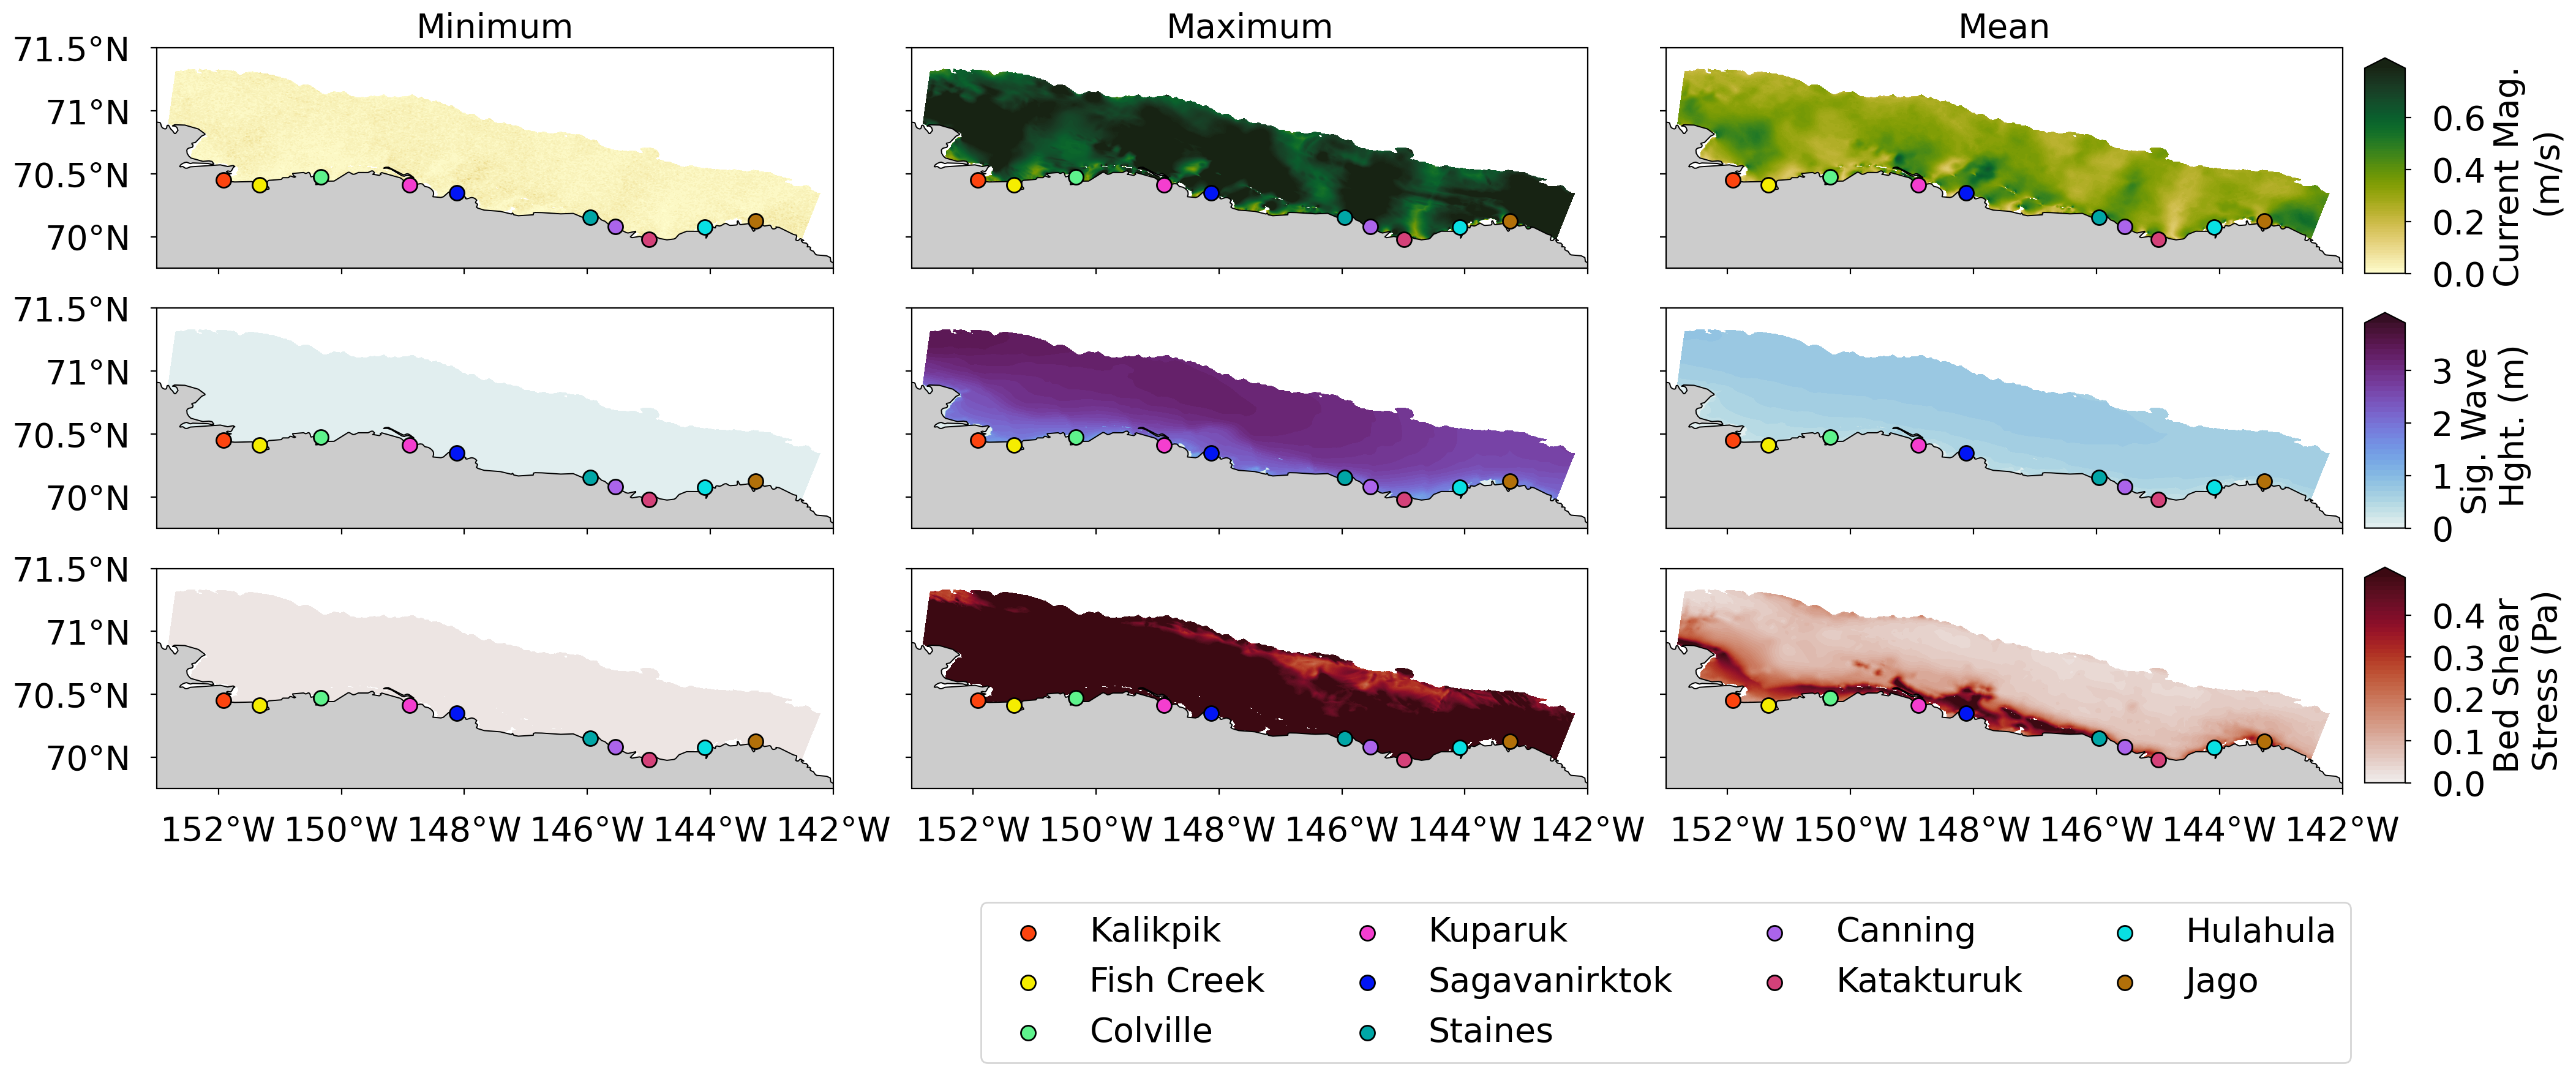

In [48]:
# Make giant plotting showing all of these things 

# Make the figure
fig1, ax1 = plt.subplots(3, 3, figsize=(22,8), dpi=200, #figsize=(16,12) (18,6) (16,6) is good ratio but too small; (20, 8) (16, 8) is good
                       #constrained_layout=True, 
                       subplot_kw={'projection': crs}) # figsize=(12,4.5). (16,6)
# Set the overall title/time
#fig1.suptitle('Time: ' + str(ds.ocean_time.values[t])[:10], x=0.5, y=1.02)

# --- Currents ---
# Min
m1 = ax1[0,0].contourf(lon_rho_trimmed, lat_rho_trimmed, min_depth_avg_cur_mag_masked_trimmed,
        cmap=cmocean.cm.speed, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_cur, vmax=vmax_cur, levels=lev_cur)

# Max
m2 = ax1[0,1].contourf(lon_rho_trimmed, lat_rho_trimmed, max_depth_avg_cur_mag_masked_trimmed,
        cmap=cmocean.cm.speed, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_cur, vmax=vmax_cur, levels=lev_cur)
# Mean
m3 = ax1[0,2].contourf(lon_rho_trimmed, lat_rho_trimmed, mean_depth_avg_cur_mag_masked_trimmed,
        cmap=cmocean.cm.speed, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_cur, vmax=vmax_cur, levels=lev_cur)

# Plot the colorbar - currents
cbar_ax1 = fig1.add_axes([0.930,0.66,0.015,0.22]) # [0.02,0.13,0.02,0.74]; [0.025,0.15,0.015,0.74]
fig1.colorbar(m1, ax=(ax1[0,:]), ticks=[0.0, 0.2, 0.4, 0.6], extend='both', orientation='vertical',
             pad=0.005, cax=cbar_ax1).set_label(label='Current Mag. \n(m/s)', size=fontsize)


# --- Waves ---
# Min
m4 = ax1[1,0].contourf(lon_rho_trimmed, lat_rho_trimmed, min_Hwave_masked_trimmed,
        cmap=cmocean.cm.dense, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_wave, vmax=vmax_wave, levels=lev_wave)

# Max
m5 = ax1[1,1].contourf(lon_rho_trimmed, lat_rho_trimmed, max_Hwave_masked_trimmed,
        cmap=cmocean.cm.dense, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_wave, vmax=vmax_wave, levels=lev_wave)
# Mean
m6 = ax1[1,2].contourf(lon_rho_trimmed, lat_rho_trimmed, mean_Hwave_masked_trimmed,
        cmap=cmocean.cm.dense, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_wave, vmax=vmax_wave, levels=lev_wave)

# Plot the colorbar - waves
cbar_ax2 = fig1.add_axes([0.930,0.40,0.015,0.22]) # [0.02,0.13,0.02,0.74]; [0.025,0.15,0.015,0.74]
fig1.colorbar(m4, ax=(ax1[1,:]), ticks=[0.0, 1, 2, 3], extend='both', orientation='vertical',
             pad=0.005, cax=cbar_ax2).set_label(label='Sig. Wave \nHght. (m)', size=fontsize)


# --- Bed Stress ---
# Min
m7 = ax1[2,0].contourf(lon_rho_trimmed, lat_rho_trimmed, min_bstrcwmax_masked_trimmed,
        cmap=cmocean.cm.amp, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_stress, vmax=vmax_stress, levels=lev_stress)

# Max
m8 = ax1[2,1].contourf(lon_rho_trimmed, lat_rho_trimmed, max_bstrcwmax_masked_trimmed,
        cmap=cmocean.cm.amp, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_stress, vmax=vmax_stress, levels=lev_stress)
# Mean
m9 = ax1[2,2].contourf(lon_rho_trimmed, lat_rho_trimmed, mean_bstrcwmax_masked_trimmed,
        cmap=cmocean.cm.amp, transform=ccrs.PlateCarree(),
        facecolor="gray", extend='max',
        vmin = vmin_stress, vmax=vmax_stress, levels=lev_stress)

# Plot the colorbar - bed stress
cbar_ax3 = fig1.add_axes([0.930,0.14,0.015,0.22]) # [0.02,0.13,0.02,0.74]; [0.025,0.15,0.015,0.74]
cbar3 = fig1.colorbar(m7, ax=(ax1[2,:]), ticks=[0.0, 0.1, 0.2, 0.3, 0.4], extend='both', orientation='vertical',
             pad=0.005, cax=cbar_ax3).set_label(label='Bed Shear \nStress (Pa)', size=fontsize)

# Loop through each row and plot
# Add in the rivers to all subplots
# Loop through the columns
for n in range(3):
        for o in range(3):
                # Set extent and map features
                #ax1[n,o].set_extent([-153.5,-141.1,69.75, 71.5],ccrs.PlateCarree()) # whole domain
                ax1[n,o].set_extent([-153,-142.2,69.75, 71.5],ccrs.PlateCarree()) # trimmed 
                ax1[n,o].add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                                                facecolor='0.8'), linewidth=.7)
                ax1[n,o].coastlines(resolution='10m', linewidth=.7)

                # Set tick locations
                xticks = [-152, -150, -148, -146, -144, -142]
                yticks = [70, 70.5, 71, 71.5]

                ax1[n,o].set_yticks(yticks, crs=ccrs.PlateCarree())
                ax1[n,o].yaxis.set_major_formatter(cticker.LatitudeFormatter())
                ax1[n,o].set_xticks(xticks, crs=ccrs.PlateCarree())
                ax1[n,o].xaxis.set_major_formatter(cticker.LongitudeFormatter())

                # ---- Remove labels for first two panels ----
                if o in [0, 1, 2] and n!= 2:
                        ax1[n,o].tick_params(labelbottom=False)
                if o in [1, 2]:
                        ax1[n,o].tick_params(labelleft=False)

                # Fix the aspect ratio
                lon_min, lon_max = -153, -142.2
                lat_min, lat_max = 69.75, 71.5
                mid_lat = (lat_min + lat_max) / 2
                aspect = (lon_max - lon_min) * np.cos(np.deg2rad(mid_lat)) / (lat_max - lat_min)
                ax1[n,o].set_aspect(aspect)

                # # Plot the gridlines and stuff?
                # gl2 = ax1[n,o].gridlines(crs=ccrs.PlateCarree(), 
                #                 draw_labels=True, 
                #                 x_inline=False, y_inline=False, 
                #                 linewidth=0.33, color='#00000000',alpha=0)
                # gl2.right_labels = gl2.top_labels = False
                # gl2.xlocator = ticker.FixedLocator([-152, -150,-148,-146,-144,-142])
                # gl2.xlabel_style = {'rotation': 0, 'ha': 'center', 'fontsize':fontsize-13}

                # if (0 <= n < 3):
                #     gl2.bottom_labels=False
                # if (o == 1):
                #     gl2.left_labels=False

                #print('o: ', o)
                # Plot the 10 rivers in the grid
                # Go from West to East
                # Kalikpik River
                eta_kal_idx = 23 #22
                xi_kal_idx = 87
                s1 = ax1[n,o].scatter(grid.lon_rho[eta_kal_idx, xi_kal_idx].values, grid.lat_rho[eta_kal_idx, xi_kal_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[0], label='Kalikpik',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Fish Creek
                eta_fis_idx = 20
                xi_fis_idx = 117 #116
                s2 = ax1[n,o].scatter(grid.lon_rho[eta_fis_idx, xi_fis_idx].values, grid.lat_rho[eta_fis_idx, xi_fis_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[1], label='Fish Creek',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Colville River
                eta_col_idx = 39
                xi_col_idx = 166 #166
                s3 = ax1[n,o].scatter(grid.lon_rho[eta_col_idx, xi_col_idx].values, grid.lat_rho[eta_col_idx, xi_col_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[2], label='Colville',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Kuparik
                # Kukpuk - Change this to be labeled as the Kuparuk since it  is actually the main channel 
                # of the Kuparuk River
                eta_kuk_idx = 41 #40
                xi_kuk_idx = 239
                eta_kup_idx = 41 #40
                xi_kup_idx = 242
                s5 = ax1[n,o].scatter(grid.lon_rho[eta_kuk_idx, xi_kuk_idx].values, grid.lat_rho[eta_kuk_idx, xi_kuk_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[4], label='Kuparuk',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Sagavanirktok River
                eta_sag_idx = 37 #36
                xi_sag_idx = 279
                s9 = ax1[n,o].scatter(grid.lon_rho[eta_sag_idx, xi_sag_idx].values, grid.lat_rho[eta_sag_idx, xi_sag_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[6], label='Sagavanirktok',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Canning River
                # Staines River
                eta_sta_idx = 27 #26
                xi_sta_idx = 393
                s10 = ax1[n,o].scatter(grid.lon_rho[eta_sta_idx, xi_sta_idx].values, grid.lat_rho[eta_sta_idx, xi_sta_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[7], label='Staines',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Canning River
                eta_can_idx = 20 #19
                xi_can_idx = 416
                s11 = ax1[n,o].scatter(grid.lon_rho[eta_can_idx, xi_can_idx].values, grid.lat_rho[eta_can_idx, xi_can_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[8], label='Canning',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Katakturuk River
                eta_kat_idx = 9 #8
                xi_kat_idx = 447
                s12 = ax1[n,o].scatter(grid.lon_rho[eta_kat_idx, xi_kat_idx].values, grid.lat_rho[eta_kat_idx, xi_kat_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[9], label='Katakturuk',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Hulahula River
                eta_hul_idx = 40
                xi_hul_idx = 489
                s13 = ax1[n,o].scatter(grid.lon_rho[eta_hul_idx, xi_hul_idx].values, grid.lat_rho[eta_hul_idx, xi_hul_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[10], label='Hulahula',
                                transform=ccrs.PlateCarree(), zorder=500)

                # Jago River
                eta_jag_idx = 62 #61
                xi_jag_idx = 528
                s14 = ax1[n,o].scatter(grid.lon_rho[eta_jag_idx, xi_jag_idx].values, grid.lat_rho[eta_jag_idx, xi_jag_idx].values, 
                                marker='.', s=300, linewidth=1, edgecolors='black', color=river_marker_colors[11], label='Jago',
                                transform=ccrs.PlateCarree(), zorder=500)

                # # If one of the first three subplots, mute the x-axis 
                # if n != (len(flow_times)-1):
                # #print('n: ', n)
                # plt.setp(ax1[n,0].get_xticklabels(), visible=False)
                # plt.setp(ax1[n,1].get_xticklabels(), visible=False)





# Make a legend
handles, labels = ax1[0,0].get_legend_handles_labels()
plt.legend(handles, labels, ncol=4, fontsize=fontsize, bbox_to_anchor=(0.07, -0.5))


# Put mini titles
ax1[0,0].set_title('Minimum', fontsize=20)
ax1[0,1].set_title('Maximum', fontsize=20)
ax1[0,2].set_title('Mean', fontsize=20)

# Set the overall title
#fig1.suptitle('Surface Salinity & Surface Stress', fontsize=fontsize-6)


# # # Make a legend
# # plt.legend(ncol=4, fontsize=fontsize-15, loc='lower right', bbox_to_anchor=(0.30, -0.9))
# # Add the colorbar
# #cbar3_ax = fig3.add_axes([0.14, -0.02, 0.74, 0.05]) #[0.14, 0.000007, 0.74, 0.05]
# #cbar3 = plt.colorbar(m2, cax=cbar3_ax, orientation='horizontal', extend='both').set_label(label='Suspended Sediment Mass (kg)', size=fontsize)

# Set layout
plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])

# # Adjust spacing between subplots
# plt.subplots_adjust(wspace=0.05, hspace=0.35) #0.08 # (0.22, 0.25) (w=0.12, h=0.45) (0.12, 0.35)

# # Add subplot labels
# fig1.text(0.132, 0.787, 'a)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.535, 0.787, 'b)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.132, 0.585, 'c)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.535, 0.585, 'd)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.132, 0.382, 'e)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.535, 0.382, 'f)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.132, 0.178, 'g)', color='black', fontsize=fontsize-13, weight='bold')
# fig1.text(0.535, 0.178, 'h)', color='black', fontsize=fontsize-13, weight='bold')



In [35]:
(mean_bustrcwmax_masked_trimmed[100,100])

<xarray.DataArray ()> Size: 8B
array(-0.02712821)
Coordinates:
    lon_rho  float64 8B -150.8
    lat_rho  float64 8B 70.82
    eta_rho  float64 8B 100.0
    xi_rho   float64 8B 136.0

In [41]:
print(np.nanmax(model_output.bustrcwmax.values))

2.8654879433334908


In [43]:
model_output.bstrcwmax


<xarray.DataArray 'bstrcwmax' (ocean_time: 738, eta_rho: 206, xi_rho: 608)> Size: 739MB
dask.array<getitem, shape=(738, 206, 608), dtype=float64, chunksize=(42, 206, 608), chunktype=numpy.ndarray>
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
    lat_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
  * ocean_time  (ocean_time) datetime64[ns] 6kB 2020-07-01T03:00:00 ... 2020-...
Dimensions without coordinates: eta_rho, xi_rho
Attributes:
    long_name:  time-averaged max wave and current bottom stress magnitude
    units:      newton meter-2
    time:       ocean_time
    grid:       grid
    location:   face
    field:      bstrcwmax, scalar, series